In [1]:
import pandas as pd

daily_return_df = pd.read_csv('sp500_joined_daily_returns_yahoo.csv')
daily_return_df.set_index('Date', inplace=True)

windows = [5,10,20,40,60]
def calc_beta_error(daily,window):
    beta = daily.rolling(window=window, min_periods=3).cov(daily['SPY']).div(daily['SPY'].rolling(window=window, min_periods=3).var(), axis=0)
    return (daily - beta.mul(daily['SPY'], axis=0)) ** 2

## Testing 
# test_daily_return_df = pd.read_csv('test/test_daily_returns.csv')
# test_daily_return_df.set_index('Date', inplace=True)

# Beta error statistics #

## Best window for all ticker ##

<AxesSubplot:xlabel='Date'>

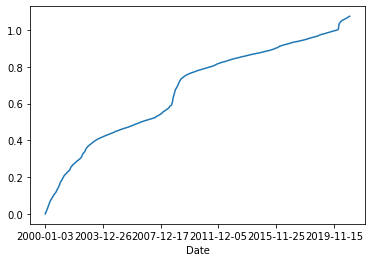

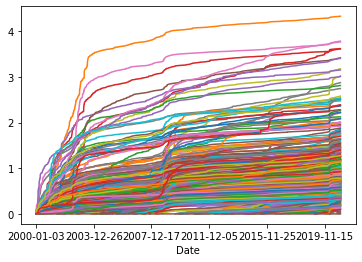

In [2]:
concat_df = None
for w in windows:
    beta_error_df = calc_beta_error(daily_return_df,w)   
    beta_error_df.columns = beta_error_df.columns + "_{0}".format(w)
    if concat_df is not None:
        concat_df = pd.concat([concat_df,beta_error_df], axis=1)
    else:
        concat_df = beta_error_df

min_beta_error_df = pd.DataFrame()
for ticker in daily_return_df.columns:
    prefix = ticker + '_'
    head = []
    for i in range(0,len(windows)):
        head.append(prefix + str(windows[i]))
    min_beta_error_df[ticker] = concat_df[head].min(axis=1)

min_beta_error_df.to_csv("Results/Min_beta_error.csv")
min_beta_error_df.mean(axis=1).cumsum(axis=0).plot()
min_beta_error_df.cumsum(axis=0).plot(legend=False)

In [3]:
# ## Test
# concat_df = None
# for w in windows:
#     beta_error_df = calc_beta_error(test_daily_return_df,w)   
#     beta_error_df.columns = beta_error_df.columns + "_{0}".format(w)
#     if concat_df is not None:
#         concat_df = pd.concat([concat_df,beta_error_df], axis=1)
#     else:
#         concat_df = beta_error_df
# concat_df.to_csv("test/best_window_concat.csv")

# min_beta_error_df = pd.DataFrame()
# for ticker in test_daily_return_df.columns:
#     prefix = ticker + '_'
#     head = []
#     for i in range(0,len(windows)):
#         head.append(prefix + str(windows[i]))
#     min_beta_error_df[ticker] = concat_df[head].min(axis=1)
# min_beta_error_df.to_csv("test/best_betas.csv")

# ## Checked, chooses the minimum values from all windows

## With fix window size ##

<AxesSubplot:xlabel='Date'>

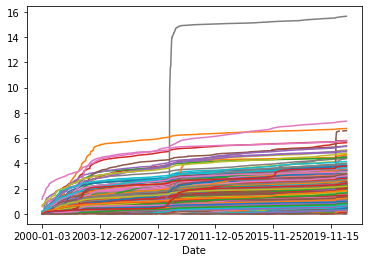

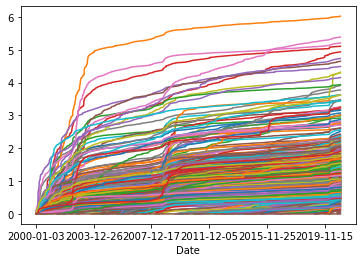

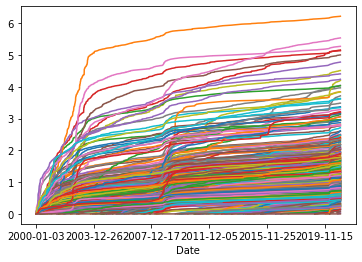

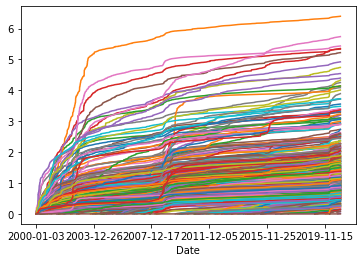

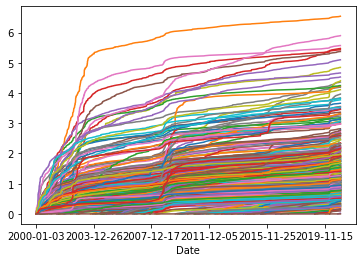

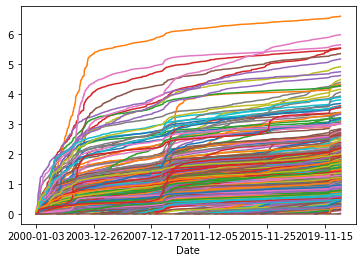

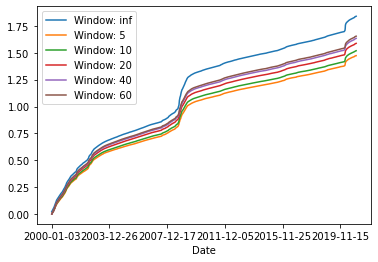

In [4]:
mean_cumsum_df = pd.DataFrame()
fix_list = []
# Infinite window
beta_df = daily_return_df.expanding().cov(daily_return_df['SPY']).div(daily_return_df['SPY'].expanding().var(), axis=0)
beta_error_df = (daily_return_df - beta_df.mul(daily_return_df['SPY'], axis=0)) ** 2
beta_error_df.cumsum().plot(legend=False)
beta_error_df.to_csv("Results/infinite_windows.csv")
mean_cumsum_df["Window: inf"] = beta_error_df.mean(axis=1).cumsum(axis=0)

for w in windows:
    beta_error_df = calc_beta_error(daily_return_df, w)
    beta_error_df.cumsum(axis=0).plot(legend=False)
    fix_list.append(beta_error_df)
    mean_cumsum_df["Window: {0}".format(w)] = beta_error_df.mean(axis=1).cumsum(axis=0)
    beta_error_df.to_csv("Results/fix_window_{}.csv".format(w))
mean_cumsum_df.plot()

# Follow the Leader #

## v.1. ##

In [5]:
concat_df = None
for w in windows:
    beta_error_df = calc_beta_error(daily_return_df,w)   
    beta_error_df.columns = beta_error_df.columns + "_{0}".format(w)
    if concat_df is not None:
        concat_df = pd.concat([concat_df, beta_error_df], axis=1)
    else:
        concat_df = beta_error_df

In [6]:
FTL_v1_df = pd.DataFrame()
for ticker in daily_return_df.columns:
    prefix = ticker + '_'
    head = []
    for i in range(0,len(windows)):
        head.append(prefix + str(windows[i]))
    cumsum_min_cols = concat_df[head].cumsum(axis=0).shift(1).idxmin(axis=1)
    for date in concat_df.index:
        if pd.isnull(cumsum_min_cols.loc[date]):
            FTL_v1_df[ticker] = None
        else:
            FTL_v1_df.loc[date,ticker] = concat_df.loc[date,cumsum_min_cols[date]]

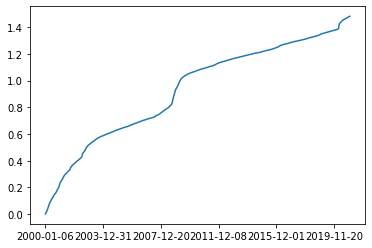

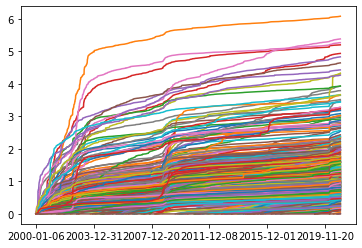

In [7]:
FTL_v1_df.mean(axis=1).cumsum(axis=0).plot()
FTL_v1_df.cumsum(axis=0).plot(legend=False)
FTL_v1_df.index.names = ['Date']
FTL_v1_df.to_csv("Results/FTL_v1.csv")

In [8]:
# ## Testing
# # concat is from best windows

# min_beta_error_df = pd.DataFrame()
# for ticker in test_daily_return_df.columns:
#     prefix = ticker + '_'
#     head = []
#     for i in range(0,len(windows)):
#         head.append(prefix + str(windows[i]))
#     concat_df[head].to_csv("test/FTL_concat_{0}.csv".format(ticker))
#     cumsum_min_cols = concat_df[head].cumsum(axis=0).shift(1).idxmin(axis=1)
#     cumsum_min_cols.to_csv("test/FTL_cumsum_min_cols{0}.csv".format(ticker))
#     for date in concat_df.index:
#         if pd.isnull(cumsum_min_cols.loc[date]):
#             min_beta_error_df[ticker] = None
#         else:
#             min_beta_error_df.loc[date,ticker] = concat_df.loc[date,cumsum_min_cols[date]]
# min_beta_error_df.to_csv("test/FTL_min_beta_error.csv")

## v.2. ##

In [9]:
# It might be easier to understand the FTL conception with iteration.
# This algorithm can be easily modify to run on smaller period, or calculate
# different windows for tickers

FTL_beta_error_df = pd.DataFrame().reindex(columns = daily_return_df.columns)
W = pd.DataFrame(0.0, index=windows, columns=['error'])
daily_return_df.index = [pd.Timestamp(x) for x in daily_return_df.index]

In [10]:
for i in range(21):
    year = 2000 + i
    print(year)
    date_indexes = [x for x in daily_return_df.index if x.year == year]
    min_window = W.idxmin()['error']
    
    daily = daily_return_df.loc[date_indexes,:]
    act_beta_error_df = calc_beta_error(daily, min_window)
    FTL_beta_error_df = pd.concat([FTL_beta_error_df, act_beta_error_df], axis=0)
    # refresh weights
    W['error'][min_window] += act_beta_error_df.sum().sum()
    for window in windows:
        if window == min_window:
            continue
        beta_error_df = calc_beta_error(daily, window)
        W['error'][window] += beta_error_df.sum().sum()

2000
2001
2002
2003
2004
2005
2006
2007
2008
2009
2010
2011
2012
2013
2014
2015
2016
2017
2018
2019
2020


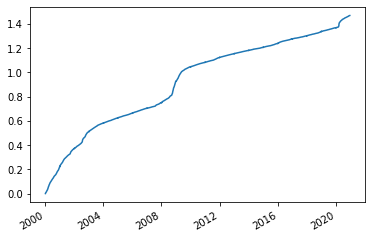

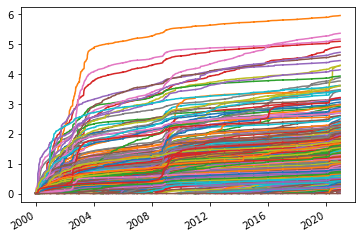

In [11]:
FTL_beta_error_df.mean(axis=1).cumsum(axis=0).plot()
FTL_beta_error_df.cumsum(axis=0).plot(legend=False)
FTL_beta_error_df.to_csv("Results/FTL_v2.csv")

In [12]:
## test
# FTL_beta_error_df = pd.DataFrame().reindex(columns = test_df.columns)
# W = pd.DataFrame(0.0, index=windows, columns=['error'])
# test_daily_return_df.index = [pd.Timestamp(x) for x in test_df.index]

# for i in range(21):
#     year = 2000 + i
#     date_indexes = [x for x in test_df.index if x.year == year]
#     min_window = W.idxmin()['error']
    
#     daily = test_daily_return_df.loc[date_indexes,:]
#     act_beta_error_df = calc_beta_error(daily, min_window)
#     FTL_beta_error_df = pd.concat([FTL_beta_error_df,act_beta_error_df], axis=0)
#     act_beta_error_df.to_csv("test/TFL2_beta_{0}.csv".format(year))
#     # refresh weights
#     W['error'][min_window] += act_beta_error_df.sum().sum()
#     for window in windows:
#         if window == min_window:
#             continue
#         beta_error_df = calc_beta_error(daily, window)
#         W['error'][window] += beta_error_df.sum().sum()
#     W.to_csv("test/W_after_{}.csv".format(year))

# ## 2000
# # window: 5, Beta sum: 0.829029484, W(5): 0.829029484286682
# ## 2001
# # window: 5, Bera sum: 0.664516009, W(5): 1.49948941
# ## 2002
# # window: 5 , Beta sum: 0.716921702, W(5): 2.210467 OK